In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\ptlha\Documents\Math & Stat\derivable_judgement_dataset.csv")

df.head()

,record_id,age_group,age,weight,gender,region,smoking_status,exercise_frequency,bmi,blood_pressure,diabetes,hypertension,cholesterol_level,glucose_level,visit_date
0,HR0001,46-60,56,58,Male,West,Non-Smoker,Rarely,22.0,126.2,False,False,238.9,117.2,2026-02-23
1,HR0002,60+,69,86,Male,East,Smoker,Daily,33.3,145.4,False,True,271.8,106.8,2024-03-04
2,HR0003,46-60,46,53,Male,North,Non-Smoker,Weekly,19.8,118.9,False,False,173.6,94.1,2026-08-02
3,HR0004,26-35,32,93,Male,East,Non-Smoker,Weekly,36.6,135.5,False,False,219.4,91.3,2025-11-16
4,HR0005,46-60,60,57,Female,North,Non-Smoker,Weekly,19.9,125.9,False,False,173.4,80.9,2025-09-21


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   record_id           500 non-null    str    
 1   age_group           500 non-null    str    
 2   age                 500 non-null    int64  
 3   weight              500 non-null    int64  
 4   gender              500 non-null    str    
 5   region              500 non-null    str    
 6   smoking_status      500 non-null    str    
 7   exercise_frequency  500 non-null    str    
 8   bmi                 500 non-null    float64
 9   blood_pressure      500 non-null    float64
 10  diabetes            500 non-null    bool   
 11  hypertension        500 non-null    bool   
 12  cholesterol_level   500 non-null    float64
 13  glucose_level       500 non-null    float64
 14  visit_date          500 non-null    str    
dtypes: bool(2), float64(4), int64(2), str(7)
memory usage: 74.1 KB


In [4]:
num_cols = ['age','weight','bmi','blood_pressure','cholesterol_level','glucose_level']
print(df[num_cols].describe().T.round(2))
print('\nDiabetes rate by smoking:')
print(df.groupby('smoking_status')['diabetes'].agg(['sum','count','mean']).round(3))

                   count    mean    std    min     25%    50%     75%    max
age                500.0   44.73  15.24   18.0   32.00   45.0   57.00   70.0
weight             500.0   70.30  13.64   42.0   61.00   70.0   80.00  114.0
bmi                500.0   25.08   5.80   12.6   21.00   24.8   28.50   49.0
blood_pressure     500.0  131.07  13.28   96.4  122.68  131.2  140.22  167.8
cholesterol_level  500.0  202.17  29.89  125.5  181.08  202.1  222.80  285.0
glucose_level      500.0   92.02  13.65   55.0   84.12   92.3  100.22  143.5

Diabetes rate by smoking:
                sum  count   mean
smoking_status                   
Former Smoker     5    106  0.047
Non-Smoker       11    285  0.039
Smoker            7    109  0.064


# Part B - Data Analysis and Statistical Testing

## 1. Hypothesis Testing

| # | Research question | $H_0$ | $H_1$ | Test |
| --- | --- | --- | --- | --- |
| **H1** | Does smoking affect diabetes prevalence? | Smoking status and diabetes are **independent** | Smoking status and diabetes are **associated** | $\chi^2$ |
| **H2** | Is the smoker diabetes rate the same as the non-smoker rate? | $p_{\text{Smoker}} = p_{\text{Non-Smoker}}$ | $p_{\text{Smoker}} \neq p_{\text{Non-Smoker}}$ | Two-proportion $z$ |
| **H3** | Do diabetics have different mean fasting glucose? | $\mu_{\text{diab}} = \mu_{\text{non-diab}}$ | $\mu_{\text{diab}} \neq \mu_{\text{non-diab}}$ | Welch $t$ |
| **H4** | Do age groups differ in mean systolic BP? | $\mu_{18\text{-}25} = \dots = \mu_{60+}$ | At least one group mean differs | One-way ANOVA |
| **H5** | Is BMI linearly related to blood pressure? | $\rho = 0$ | $\rho \neq 0$ | Pearson $r$ |

## 2. 95% Confidence Interval for Age

A 95% confidence interval is calculated to estimate the range of possible values for the population mean age.

In [5]:
age_mean = df["age"].mean()

age_sem = stats.sem(df["age"])

confidence_interval = stats.t.interval(
    confidence=0.95,
    df=len(df["age"]) - 1,
    loc=age_mean,
    scale=age_sem
)

print("Mean Age:", age_mean)
print("95% Confidence Interval:", confidence_interval)

Mean Age: 44.732
95% Confidence Interval: (np.float64(43.392957501932855), np.float64(46.07104249806714))


## Interpretation: We are 95% confident that the population mean age lies within the calculated confidence interval.

## 3. Critical Value and P-value

The critical value is used as a cutoff for deciding whether a statistical result falls in the rejection region. The p-value helps determine whether there is sufficient evidence against H₀.

In [6]:
n = len(df)
print("z*     :", stats.norm.ppf(0.975))           
print("t*     :", stats.t.ppf(0.975, 499))             
print("chi2*  :", stats.chi2.ppf(0.95, 2))
print("F*     :", stats.f.ppf(0.95, 4, 495))
print("r*     :", stats.norm.ppf(0.975)/np.sqrt(n))

z*     : 1.959963984540054
t*     : 1.9647293909876886
chi2*  : 5.991464547107979
F*     : 2.389947844458197
r*     : 0.08765225405765815


## 4. Z-Test

In [7]:
# 4a. one-proportion

n = len(df)
x = df['diabetes'].sum()

p = x / n
p0 = 0.25

se = np.sqrt(p0 * (1 - p0) / n)

z = (p - p0) / se

p_value = 2 * (1 - stats.norm.cdf(abs(z)))

print("Total Records:", n)
print("Diabetes Cases:", x)
print("Proportion:", p)
print("Z Value:", z)
print("P Value:", format(p_value,'.4e'))

if p_value < 0.05:
    print("Reject H0")
else:
    print("Fail to reject H0")

Total Records: 500
Diabetes Cases: 23
Proportion: 0.046
Z Value: -10.534514701684175
P Value: 0.0000e+00
Reject H0


## **Interpretation:**

The one-proportion Z-test checks whether the diabetes proportion differs significantly from the hypothesized proportion of 25%.

If the p-value is less than 0.05, we reject the null hypothesis. Otherwise, we fail to reject the null hypothesis.

In [8]:
# 4b. two-proportion: Smoker vs Non-Smoker

from statsmodels.stats.proportion import proportions_ztest

smoker = df[df['smoking_status'] == 'Smoker']
non_smoker = df[df['smoking_status'] == 'Non-Smoker']

x1 = smoker['diabetes'].sum()
x2 = non_smoker['diabetes'].sum()

n1 = len(smoker)
n2 = len(non_smoker)

z, p = proportions_ztest([x1, x2], [n1, n2])

print("Smoker Cases:", x1)
print("Non-Smoker Cases:", x2)
print("Z Value:", round(z, 3))
print("P Value:", format(p, '.4e'))

if p < 0.05:
    print("Reject H0")
else:
    print("Fail to reject H0")

Smoker Cases: 7
Non-Smoker Cases: 11
Z Value: 1.09
P Value: 2.7586e-01
Fail to reject H0


## **Interpretation:**

The two-proportion Z-test compares the diabetes proportions of smokers and non-smokers.

If the p-value is less than 0.05, there is a statistically significant difference between the two proportions. Otherwise, there is insufficient evidence of a significant difference.

## 5. WELCH T-TEST

In [9]:
g1 = df[df['diabetes'] == True]['glucose_level']
g0 = df[df['diabetes'] == False]['glucose_level']

t, p = stats.ttest_ind(g1, g0, equal_var=False)

print("T Value:", round(t, 3))
print("P Value:", round(p, 4))

if p < 0.05:
    print("Reject H0")
else:
    print("Fail to reject H0")

T Value: 3.911
P Value: 0.0007
Reject H0


## **Interpretation:**

Welch's T-test compares the mean glucose levels of people with diabetes and people without diabetes.

If the p-value is less than 0.05, we reject the null hypothesis and conclude that the mean glucose levels differ significantly. Otherwise, we fail to reject the null hypothesis.

## 6. Chi-Square Test of Independence

In [10]:
table = pd.crosstab(df['smoking_status'], df['diabetes'])

chi, p, dof, expected = stats.chi2_contingency(
    table, correction=False
)

print("Chi-Square Value:", round(chi, 3))
print("P Value:", round(p, 4))
print("Degrees of Freedom:", dof)

if p < 0.05:
    print("Reject H0")
else:
    print("Fail to reject H0")

Chi-Square Value: 1.184
P Value: 0.5533
Degrees of Freedom: 2
Fail to reject H0


## **Interpretation:**

The Chi-square test was used to examine the association between smoking status and diabetes. The calculated Chi-square value is 1.184, and the p-value is 0.5533.

Since the p-value (0.5533) is greater than the significance level (0.05), we fail to reject the null hypothesis. Therefore, the dataset does not provide sufficient statistical evidence of a significant association between smoking status and diabetes.

## 6. ANOVA Test: BMI Across Age Groups

#### H₀-There is no significant difference in mean BMI among the age groups.

#### H₁-At least one age group has a significantly different mean BMI.

#### Significance Level α = 0.05

In [11]:
g1 = df[df['age_group'] == '18-25']['blood_pressure']
g2 = df[df['age_group'] == '26-35']['blood_pressure']
g3 = df[df['age_group'] == '36-45']['blood_pressure']
g4 = df[df['age_group'] == '46-60']['blood_pressure']
g5 = df[df['age_group'] == '60+']['blood_pressure']

F, p = stats.f_oneway(g1, g2, g3, g4, g5)

print("F Value:", round(F, 3))
print("P Value:", format(p, '.4e'))

if p < 0.05:
    print("Reject H0")
else:
    print("Fail to reject H0")

F Value: 45.73
P Value: 1.0693e-32
Reject H0


## **Interpretation:**

One-way ANOVA was performed to compare the mean blood pressure across five age groups. The calculated F-value is 45.730, and the p-value is 1.0693 × 10⁻³².

Since the p-value is less than the significance level of 0.05, we reject the null hypothesis. Therefore, there is a statistically significant difference in mean blood pressure among the age groups. At least one age group's mean differs from another.

## 7. Covariance & Correlation

In [12]:
pairs = [('age','bmi'), ('bmi','blood_pressure'), ('age','blood_pressure'),
         ('cholesterol_level','blood_pressure')]
corr_rows = []
for a, b in pairs:
    cov = np.cov(df[a], df[b], ddof=1)[0,1]
    r, p_r = stats.pearsonr(df[a], df[b])
    rs, _ = stats.spearmanr(df[a], df[b])
    corr_rows.append({'pair': f'{a} vs {b}', 'cov': round(cov,3),
                      'pearson_r': round(r,3), 'p_value': f'{p_r:.3e}',
                      'spearman': round(rs,3),
                      'decision': 'Reject H0' if p_r < 0.05 else 'Fail to reject H0'})
print('\nCovariance & Correlation:')
print(pd.DataFrame(corr_rows).to_string(index=False))


Covariance & Correlation:
                               pair     cov  pearson_r   p_value  spearman          decision
                         age vs bmi  -1.662     -0.019 6.749e-01    -0.007 Fail to reject H0
              bmi vs blood_pressure  35.299      0.458 2.604e-27     0.451         Reject H0
              age vs blood_pressure 111.503      0.551 5.069e-41     0.549         Reject H0
cholesterol_level vs blood_pressure 175.512      0.442 2.403e-25     0.419         Reject H0


# 8. VISUALISATIONS

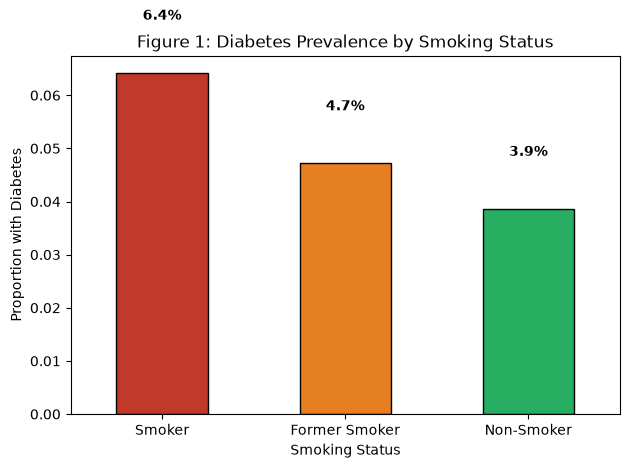

In [13]:
# 10.1 Diabetes rate by smoking status
rate = df.groupby('smoking_status')['diabetes'].mean().sort_values(ascending=False)
ax = rate.plot(kind='bar', color=['#c0392b','#e67e22','#27ae60'], edgecolor='k')
ax.set_title('Figure 1: Diabetes Prevalence by Smoking Status')
ax.set_ylabel('Proportion with Diabetes'); ax.set_xlabel('Smoking Status')
plt.xticks(rotation=0)
for i, v in enumerate(rate.values):
    ax.text(i, v + 0.01, f'{v:.1%}', ha='center', fontweight='bold')
plt.tight_layout(); plt.savefig('fig1_diabetes_by_smoking.png', dpi=150); plt.show()

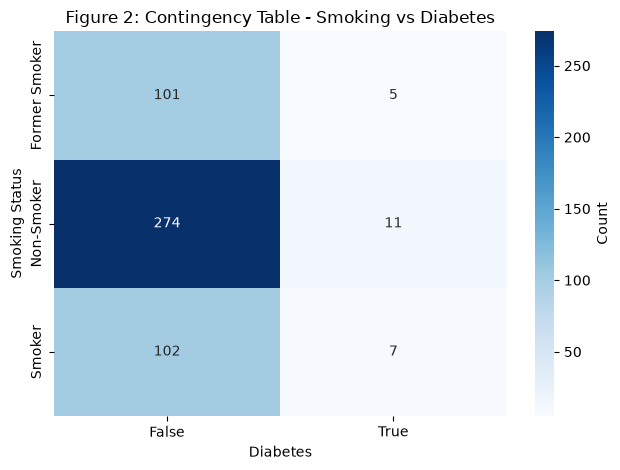

In [14]:
# 10.2 Contingency heatmap
sns.heatmap(table, annot=True, fmt='d', cmap='Blues',
            cbar_kws={'label': 'Count'})
plt.title('Figure 2: Contingency Table - Smoking vs Diabetes')
plt.ylabel('Smoking Status'); plt.xlabel('Diabetes')
plt.tight_layout(); plt.savefig('fig2_contingency_heatmap.png', dpi=150); plt.show()

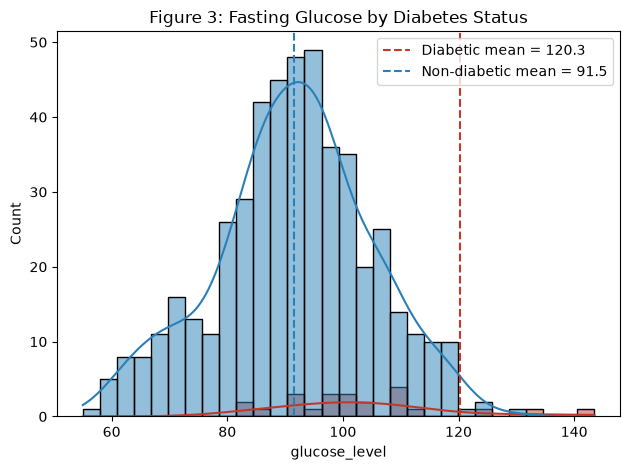

In [15]:
# 10.3 Glucose distribution by diabetes status
sns.histplot(data=df, x='glucose_level', hue='diabetes', kde=True,
             bins=30, palette={True:'#c0392b', False:'#2980b9'})
plt.axvline(g1.mean(), color='#c0392b', ls='--', label=f'Diabetic mean = {g1.mean():.1f}')
plt.axvline(g0.mean(), color='#2980b9', ls='--', label=f'Non-diabetic mean = {g0.mean():.1f}')
plt.title('Figure 3: Fasting Glucose by Diabetes Status')
plt.legend()
plt.tight_layout(); plt.savefig('fig3_glucose_dist.png', dpi=150); plt.show()

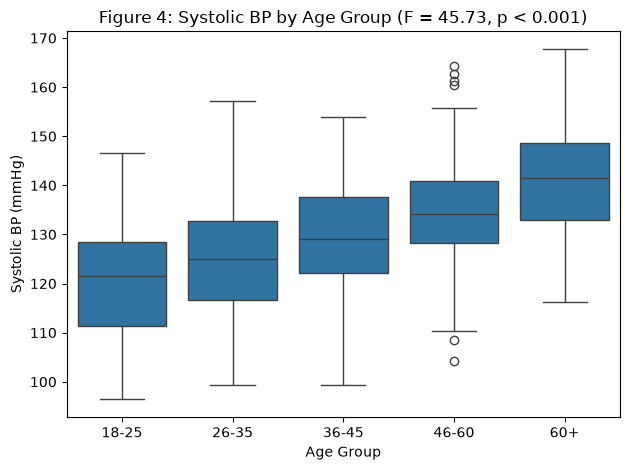

In [16]:
# 10.4 BP by age group (ANOVA visual)
sns.boxplot(data=df, x='age_group', y='blood_pressure',
            order=['18-25','26-35','36-45','46-60','60+'])
plt.title(f'Figure 4: Systolic BP by Age Group (F = {F:.2f}, p < 0.001)')
plt.ylabel('Systolic BP (mmHg)'); plt.xlabel('Age Group')
plt.tight_layout(); plt.savefig('fig4_bp_by_age.png', dpi=150); plt.show()

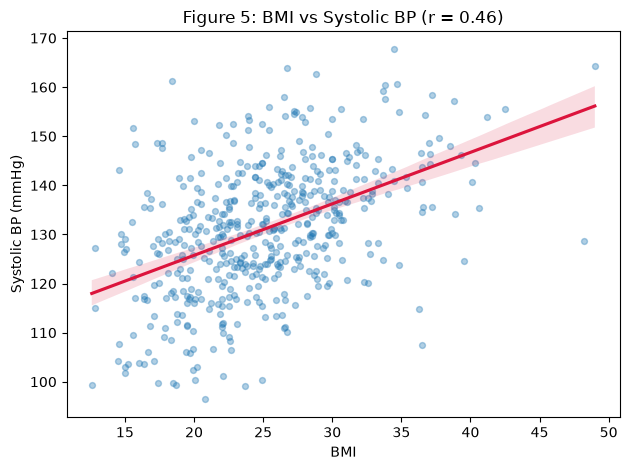

In [17]:
# 10.5 Scatter: BMI vs BP with regression line
sns.regplot(data=df, x='bmi', y='blood_pressure',
            scatter_kws={'alpha':0.35, 's':18}, line_kws={'color':'crimson'})
r_bmi_bp = stats.pearsonr(df['bmi'], df['blood_pressure'])[0]
plt.title(f'Figure 5: BMI vs Systolic BP (r = {r_bmi_bp:.2f})')
plt.xlabel('BMI'); plt.ylabel('Systolic BP (mmHg)')
plt.tight_layout(); plt.savefig('fig5_bmi_bp_scatter.png', dpi=150); plt.show()

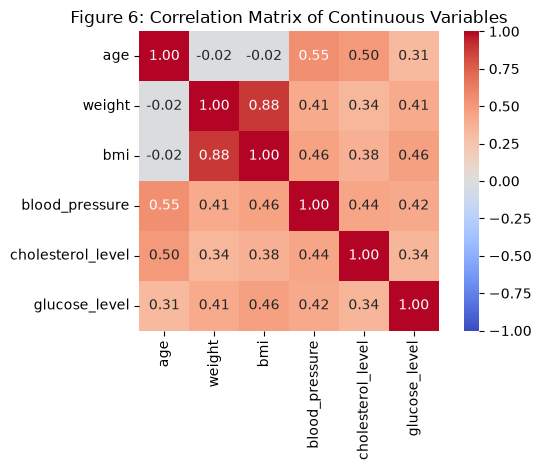

In [18]:
# 10.6 Correlation matrix heatmap
corr_matrix = df[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, square=True)
plt.title('Figure 6: Correlation Matrix of Continuous Variables')
plt.tight_layout(); plt.savefig('fig6_corr_matrix.png', dpi=150); plt.show()